# LVVO 1k four-class detection EDA

**Target:** manually annotated LVVO 1k with categories (Table, Chart-Graph, Photographic-image, Visual-illustration). The single-class 1k and automatically annotated 3k archives are deliberately excluded. This notebook downloads the archive directly from the [authors’ repository](https://github.com/dbiswas55/LVVO_dataset) / [public Drive folder](https://drive.google.com/drive/folders/1RJjj71CAQHnRLqcWIYmJbWj_1zGmw2bO), verifies it, then inspects every image and label. The [paper](https://arxiv.org/abs/2506.13657) describes the annotation origin. No model is evaluated here.

**Holdout rule:** this release does not advertise a train/validation/test split. Reading all labels here does not create an unseen final test. A later benchmark needs a video-grouped split and a separately held-out test.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
from io import BytesIO
import hashlib, json, re, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import gdown

SOURCE_REPO = "https://github.com/dbiswas55/LVVO_dataset"
FOLDER_URL = "https://drive.google.com/drive/folders/1RJjj71CAQHnRLqcWIYmJbWj_1zGmw2bO"
FILE_ID = "1oVufdcjhs76uDmEGu63vywKUXy5ZQSVF"
EXPECTED_NAME = "LVVO_1k_withCategories.zip"
ROOT = Path.cwd()
DATA_DIR = ROOT / "experiments" / "outputs" / "lvvo_four_class_eda" if (ROOT / "experiments").exists() else ROOT / "lvvo_four_class_eda"
DATA_DIR.mkdir(parents=True, exist_ok=True)
ARCHIVE = DATA_DIR / EXPECTED_NAME
if not ARCHIVE.exists():
    downloaded = gdown.download(id=FILE_ID, output=str(ARCHIVE), quiet=False)
    if not downloaded:
        raise RuntimeError("Official LVVO four-class archive could not be downloaded; EDA is HOLD.")
archive_sha256 = hashlib.sha256(ARCHIVE.read_bytes()).hexdigest()
print(pd.DataFrame([dict(source=FOLDER_URL, file_id=FILE_ID, archive=EXPECTED_NAME,
                         bytes=ARCHIVE.stat().st_size, sha256=archive_sha256)]).to_string(index=False))


                                                                  source                           file_id                    archive    bytes                                                           sha256
https://drive.google.com/drive/folders/1RJjj71CAQHnRLqcWIYmJbWj_1zGmw2bO 1oVufdcjhs76uDmEGu63vywKUXy5ZQSVF LVVO_1k_withCategories.zip 51146225 f049217c51c45d532f394d7082e69da95397dee106fede1d743ff3dee80bf7cf


## Archive integrity and safe extraction

Every member is CRC checked. Extraction rejects traversal and symlinks and writes only into the dedicated ignored output directory. The source file hash identifies this exact snapshot; the notebook does not assume a permanent hash for future upstream revisions.

In [2]:
EXTRACT_DIR = DATA_DIR / "source"
with zipfile.ZipFile(ARCHIVE) as z:
    bad_crc = z.testzip()
    if bad_crc:
        raise RuntimeError(f"Corrupt archive member: {bad_crc}")
    members = [m for m in z.infolist() if not m.filename.startswith("__MACOSX/") and not m.filename.endswith(".DS_Store")]
    for m in members:
        target = (EXTRACT_DIR / m.filename).resolve()
        if not target.is_relative_to(EXTRACT_DIR.resolve()):
            raise RuntimeError(f"Unsafe archive path: {m.filename}")
        if (m.external_attr >> 16) & 0o170000 == 0o120000:
            raise RuntimeError(f"Symlink in archive: {m.filename}")
    for m in members:
        target = EXTRACT_DIR / m.filename
        if m.is_dir():
            target.mkdir(parents=True, exist_ok=True)
        elif not target.exists() or target.stat().st_size != m.file_size:
            target.parent.mkdir(parents=True, exist_ok=True)
            with z.open(m) as src, target.open("wb") as dst:
                import shutil
                shutil.copyfileobj(src, dst)

dataset_root = EXTRACT_DIR / "LVVO_1k_withCategories"
image_paths = {p.stem: p for p in (dataset_root / "images").glob("*.jpg")}
label_paths = {p.stem: p for p in (dataset_root / "labels").glob("*.json")}
meta = json.loads((dataset_root / "dataset_info.json").read_text(encoding="utf-8"))
class_names = {int(v): k for k, v in meta["categories"].items()}
print("Archive members:", len(members), "images:", len(image_paths), "labels:", len(label_paths), "classes:", class_names)
print("Image without label:", len(image_paths.keys() - label_paths.keys()), "label without image:", len(label_paths.keys() - image_paths.keys()))


Archive members: 2004 images: 1000 labels: 1000 classes: {1: 'Table', 2: 'Chart-Graph', 3: 'Photographic-image', 4: 'Visual-illustration'}
Image without label: 0 label without image: 0


## Complete image and annotation audit

All image files are decoded. Counts below use explicit denominators. The filename `v` token is treated as a **candidate video grouping**, not verified against source URLs. Image dimensions in labels must match decoded pixels. Bounding boxes use the released pixel coordinate convention.

In [3]:
rows, box_rows, errors = [], [], []
for stem in sorted(image_paths.keys() | label_paths.keys()):
    ip, lp = image_paths.get(stem), label_paths.get(stem)
    if not ip or not lp:
        errors.append(dict(stem=stem, issue="missing_pair"))
        continue
    try:
        with Image.open(ip) as im:
            im.load()
            width, height = im.size
        raw = ip.read_bytes()
        d = json.loads(lp.read_text(encoding="utf-8"))
    except Exception as exc:
        errors.append(dict(stem=stem, issue=f"read_error:{type(exc).__name__}"))
        continue
    asset = d.get("asset", {})
    size = asset.get("size", {})
    dims_match = (size.get("width"), size.get("height")) == (width, height)
    name_match = asset.get("name") == ip.name
    video_match = re.search(r"_v(\d+)_", stem)
    course_match = re.search(r"_c(\d+)_", stem)
    instructor_match = re.match(r"i(\d+)_", stem)
    rows.append(dict(stem=stem, image=ip.name, width=width, height=height,
                     image_id=asset.get("image_id"), video_id=video_match.group(1) if video_match else None,
                     course_id=course_match.group(1) if course_match else None,
                     instructor_id=instructor_match.group(1) if instructor_match else None,
                     n_objects=len(d.get("objects", [])), dimensions_match=dims_match,
                     asset_name_match=name_match,
                     image_id_map_match=meta.get("image_id_map", {}).get(ip.name) == asset.get("image_id"),
                     image_sha256=hashlib.sha256(raw).hexdigest()))
    for i, obj in enumerate(d.get("objects", [])):
        b = obj.get("boundingBox", {})
        x1, y1, x2, y2 = (b.get(k) for k in ("xmin", "ymin", "xmax", "ymax"))
        numeric = all(isinstance(v, (int, float)) for v in (x1, y1, x2, y2))
        valid = bool(numeric and 0 <= x1 < x2 <= width and 0 <= y1 < y2 <= height)
        box_rows.append(dict(stem=stem, object_index=i, class_id=obj.get("class"),
                             class_name=class_names.get(obj.get("class"), "UNKNOWN"),
                             xmin=x1, ymin=y1, xmax=x2, ymax=y2, valid_geometry=valid,
                             stored_width_match=numeric and b.get("width") == x2-x1,
                             stored_height_match=numeric and b.get("height") == y2-y1,
                             area_fraction=((x2-x1)*(y2-y1)/(width*height)) if valid else np.nan))

images = pd.DataFrame(rows)
boxes = pd.DataFrame(box_rows)
issues = pd.DataFrame(errors)
summary = pd.DataFrame([dict(source_images=len(image_paths), source_labels=len(label_paths),
    paired_and_decoded=len(images), missing_pair=len(image_paths.keys() ^ label_paths.keys()),
    failed_reads=len(issues) - len(image_paths.keys() ^ label_paths.keys()),
    boxes=len(boxes), invalid_boxes=int((~boxes.valid_geometry).sum()),
    dimensions_mismatch=int((~images.dimensions_match).sum()),
    asset_name_mismatch=int((~images.asset_name_match).sum()),
    image_id_map_mismatch=int((~images.image_id_map_match).sum()),
    zero_object_images=int((images.n_objects == 0).sum()),
    unknown_class=int((boxes.class_name == "UNKNOWN").sum()),
    unique_v_tokens=images.video_id.nunique())])
display(summary)
display(issues.head(20))


,source_images,source_labels,paired_and_decoded,missing_pair,failed_reads,boxes,invalid_boxes,dimensions_mismatch,asset_name_mismatch,image_id_map_mismatch,zero_object_images,unknown_class,unique_v_tokens
0,1000,1000,1000,0,0,1580,0,0,0,0,21,0,139


""


## Class balance, box scale, and source grouping

,boxes,images,box_share
class_name,,,
Visual-illustration,990,644,0.626582
Chart-Graph,293,226,0.185443
Photographic-image,204,136,0.129114
Table,93,81,0.058861


,objects_per_image
count,1000.000000
mean,1.580000
std,1.119309
min,0.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,14.000000


,box_area_fraction
count,1580.000000
mean,0.176728
std,0.142351
min,0.007090
1%,0.015946
5%,0.028546
25%,0.069941
50%,0.134139
75%,0.246298
95%,0.459221


,instructor_frames,course_frames,video_frames
1,86.0,NaN,NaN
116,209.0,NaN,NaN
1736,52.0,NaN,NaN
2,113.0,NaN,NaN
311,NaN,26.0,NaN
3225,177.0,NaN,NaN
328,NaN,52.0,NaN
332,NaN,16.0,NaN
390,NaN,115.0,NaN
393,NaN,71.0,NaN


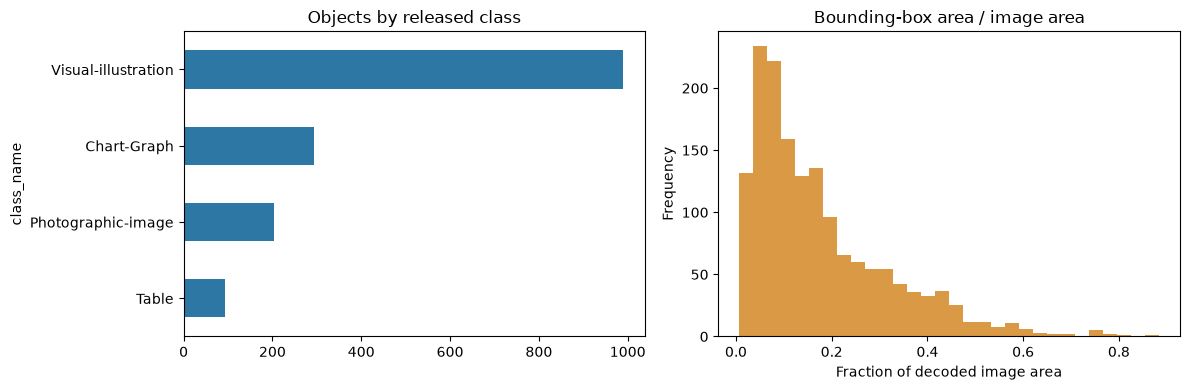

In [4]:
class_counts = boxes.groupby("class_name").agg(boxes=("stem", "size"), images=("stem", "nunique"))
class_counts["box_share"] = class_counts.boxes / len(boxes)
display(class_counts.sort_values("boxes", ascending=False))
display(images.n_objects.describe().to_frame("objects_per_image"))
display(boxes.area_fraction.describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).to_frame("box_area_fraction"))
display(pd.DataFrame({"instructor_frames": images.instructor_id.value_counts(),
                      "course_frames": images.course_id.value_counts(),
                      "video_frames": images.video_id.value_counts()}).head(20))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
class_counts.boxes.sort_values().plot.barh(ax=ax[0], color="#2d77a5", title="Objects by released class")
boxes.area_fraction.dropna().plot.hist(bins=30, ax=ax[1], color="#da9944", title="Bounding-box area / image area")
ax[1].set_xlabel("Fraction of decoded image area")
plt.tight_layout(); plt.show()


## Duplicate and split leakage checks

The archive has no official split field. Exact SHA-256 duplicates and perceptual dHash candidates (Hamming distance ≤4) are checked globally. A dHash match is a **review flag**, not proof that two labels or frames are interchangeable. Cross-split leakage cannot be quantified until a split exists. A future split must group by source video (and review course/instructor relations).

In [5]:
dupe = images.groupby("image_sha256").agg(count=("stem", "size"), examples=("stem", lambda s: list(s)[:5])).query("count > 1")
def dhash(path):
    with Image.open(path) as im:
        a = np.asarray(im.convert("L").resize((9, 8), Image.Resampling.LANCZOS))
    value = 0
    for bit in (a[:, 1:] > a[:, :-1]).ravel():
        value = (value << 1) | int(bit)
    return value

perceptual = [(r.stem, r.video_id, dhash(image_paths[r.stem])) for r in images.itertuples()]
sha_by_stem = dict(zip(images.stem, images.image_sha256))
near_pairs = []
for i, (left_stem, left_video, left_hash) in enumerate(perceptual):
    for right_stem, right_video, right_hash in perceptual[i+1:]:
        distance = (left_hash ^ right_hash).bit_count()
        if distance <= 4 and sha_by_stem[left_stem] != sha_by_stem[right_stem]:
            near_pairs.append((left_stem, right_stem, distance, left_video == right_video))
near = pd.DataFrame(near_pairs, columns=["left", "right", "dhash_distance", "same_v_token"])
display(pd.DataFrame([dict(duplicate_hash_groups=len(dupe), duplicate_images=int(dupe["count"].sum()) if len(dupe) else 0,
                           duplicate_image_ids=int(images.image_id.duplicated().sum()),
                           near_duplicate_candidate_pairs=len(near),
                           near_duplicate_cross_v_token=int((~near.same_v_token).sum()) if len(near) else 0,
                           split_column_present=False, split_leakage_status="HOLD: no released split")]))
display(dupe.head(15))
display(near.head(20))
print("Top candidate video groups:")
display(images.video_id.value_counts().head(15).rename_axis("v token").to_frame("frames"))


,duplicate_hash_groups,duplicate_images,duplicate_image_ids,near_duplicate_candidate_pairs,near_duplicate_cross_v_token,split_column_present,split_leakage_status
0,0,0,0,313,257,False,HOLD: no released split


,count,examples
image_sha256,,


,left,right,dhash_distance,same_v_token
0,i116_c425_v7654_i_1674,i116_c426_v7548_i_1222,3,False
1,i1736_c328_v6011_i_0076,i1736_c328_v6011_i_0351,4,True
2,i1_c430_v7431_i_0978,i3225_c415_v7344_i_1136,3,False
3,i1_c430_v7450_i_0186,i1_c430_v7668_i_0005,4,False
4,i1_c430_v7489_i_1802,i3225_c415_v7250_i_1595,4,False
5,i1_c430_v7657_i_1926,i2_c418_v7387_i_0048,4,False
6,i1_c430_v7657_i_1926,i3225_c415_v7213_i_0331,4,False
7,i1_c430_v7657_i_1926,i3225_c415_v7244_i_0714,4,False
8,i1_c430_v7657_i_1926,i3225_c415_v7303_i_0615,3,False
9,i1_c430_v7657_i_1926,i3225_c415_v7303_i_1141,2,False


Top candidate video groups:


,frames
v token,
7605,28
7242,25
7606,25
6992,23
7194,22
7211,22
7210,18
7573,13
7185,13


## Deterministic visual examples and unusual cases

One image per class is selected by sorted filename, then all released boxes are drawn. These four examples are a **sample** and cannot establish label quality for the entire corpus. Full image decoding and geometry validation above cover all files.

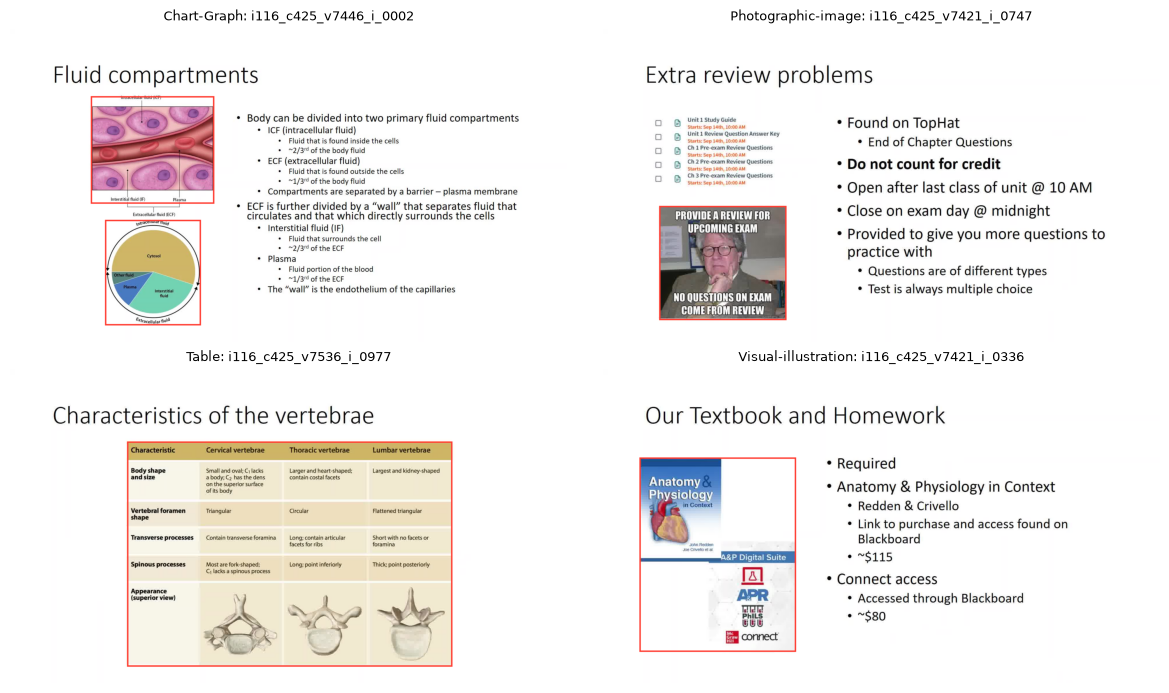

Smallest valid boxes:


,stem,class_name,area_fraction
410,i1_c311_v5765_i_0826,Photographic-image,0.007090
1128,i4642_c393_v6958_i_2110,Visual-illustration,0.007288
756,i2_c427_v7567_i_1747,Visual-illustration,0.008823
458,i1_c430_v7431_i_0710,Visual-illustration,0.008986
314,i116_c426_v7679_i_0286,Visual-illustration,0.009708


Largest valid boxes:


,stem,class_name,area_fraction
440,i1_c311_v5878_i_1460,Visual-illustration,0.883830
419,i1_c311_v5833_i_0075,Table,0.816432
1101,i4642_c393_v6957_i_1125,Photographic-image,0.784038
1099,i4642_c393_v6957_i_0730,Photographic-image,0.779297
602,i2_c418_v7329_i_1780,Visual-illustration,0.748828


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, name in zip(axes.ravel(), sorted(class_names.values())):
    subset = boxes[boxes.class_name == name]
    if subset.empty:
        ax.set_title(name + ": no box"); ax.axis("off"); continue
    stem = sorted(subset.stem.unique())[0]
    im = Image.open(image_paths[stem]).convert("RGB")
    draw = ImageDraw.Draw(im)
    for _, b in boxes[boxes.stem == stem].iterrows():
        if b.valid_geometry:
            draw.rectangle((b.xmin,b.ymin,b.xmax,b.ymax), outline="#ff3b30", width=5)
    ax.imshow(im); ax.set_title(f"{name}: {stem}", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()
print("Smallest valid boxes:")
display(boxes[boxes.valid_geometry].nsmallest(5, "area_fraction")[["stem","class_name","area_fraction"]])
print("Largest valid boxes:")
display(boxes[boxes.valid_geometry].nlargest(5, "area_fraction")[["stem","class_name","area_fraction"]])


## Decision and reproducibility receipt

This notebook qualifies **the retrieved annotation snapshot**, subject to the printed QA issues. It does not certify copyright permissions, source-video URLs, expert annotation agreement, group-safe splits, or benchmark outcomes. The release describes manually annotated boxes for four visual categories, but an independent provenance/rights review remains needed before a formal benchmark. No untouched final test exists after this all-label EDA.

In [7]:
blocking = int(summary.invalid_boxes.iloc[0] + summary.dimensions_mismatch.iloc[0] +
               summary.asset_name_mismatch.iloc[0] + summary.image_id_map_mismatch.iloc[0] + summary.unknown_class.iloc[0] +
               summary.missing_pair.iloc[0] + summary.failed_reads.iloc[0])
decision = "REPAIR/HOLD" if blocking else "KEEP for four-class EDA; HOLD formal benchmark until rights, provenance and video-grouped split are verified"
receipt = dict(source_repo=SOURCE_REPO, source_folder=FOLDER_URL, file_id=FILE_ID,
               archive=EXPECTED_NAME, archive_sha256=archive_sha256, archive_bytes=ARCHIVE.stat().st_size,
               selected_images=len(image_paths), decoded_images=len(images), selected_labels=len(label_paths),
               boxes=len(boxes), class_names=class_names, blocking_qa_count=blocking, decision=decision,
               media_scope="all image files decoded", label_scope="all JSON files parsed",
               split_scope="no official split in archive; no unseen test", extra_archives_used=False)
(DATA_DIR / "eda_receipt.json").write_text(json.dumps(receipt, indent=2), encoding="utf-8")
images.to_csv(DATA_DIR / "image_ledger.csv", index=False)
boxes.to_csv(DATA_DIR / "box_ledger.csv", index=False)
print(json.dumps(receipt, indent=2))


{
  "source_repo": "https://github.com/dbiswas55/LVVO_dataset",
  "source_folder": "https://drive.google.com/drive/folders/1RJjj71CAQHnRLqcWIYmJbWj_1zGmw2bO",
  "file_id": "1oVufdcjhs76uDmEGu63vywKUXy5ZQSVF",
  "archive": "LVVO_1k_withCategories.zip",
  "archive_sha256": "f049217c51c45d532f394d7082e69da95397dee106fede1d743ff3dee80bf7cf",
  "archive_bytes": 51146225,
  "selected_images": 1000,
  "decoded_images": 1000,
  "selected_labels": 1000,
  "boxes": 1580,
  "class_names": {
    "1": "Table",
    "2": "Chart-Graph",
    "3": "Photographic-image",
    "4": "Visual-illustration"
  },
  "blocking_qa_count": 0,
  "decision": "KEEP for four-class EDA; HOLD formal benchmark until rights, provenance and video-grouped split are verified",
  "media_scope": "all image files decoded",
  "label_scope": "all JSON files parsed",
  "split_scope": "no official split in archive; no unseen test",
  "extra_archives_used": false
}


## Qualification follow-up — 2026-10-10

Earlier executed outputs are retained as historical evidence. This additive review supersedes their current availability/qualification statements where explicitly recorded in the receipt. KEEP and REPAIR are scoped record-quality decisions, not approval of a benchmark cohort.

In [8]:
from pathlib import Path
import json, hashlib
import pandas as pd
from IPython.display import display, Markdown, Image
saved = json.loads('{"dataset": "lvvo", "observed_at_utc": "2026-10-10T08:58:45.152428+00:00", "counts": {"selected": 1000, "observed": 1000, "label_valid": 1000, "media_valid": 1000, "evaluated": 0, "failed": 0}, "artifacts": [{"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\lvvo-id-ledger.csv", "sha256": "5dd58e135b84e9e363dbdd1fddb6fa7b93d7c569238d237aa18549eabc39e2dd", "rows": 1000}, {"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\lvvo-video-group-ledger.csv", "sha256": "a61ad8c1348aef30899c7b26aecc272dd45e3946560f21793187fdd139dcc9c5", "rows": 139}, {"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\lvvo-historical-displayed-duplicate-pairs.csv", "sha256": "f98ca9b4d8ed95b901d80227b715f3448feff2e2fb14c6d7bb45072dfea322f3", "rows": 20}, {"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\lvvo-network-probes.json", "sha256": "4a245e997732ae1477657e2782aad22a1c059d1fa3e9bfb952540cccd9fecdd1"}, {"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\lvvo-provisional-split-design.json", "sha256": "4a77563dbbc2195ef676a8aa12734ca9316311429dc8e7df799ba7716195fb44"}], "model_inference_run": false, "unseen_reference_claim": false, "status": "HOLD_formal_benchmark", "evidence_reused": [{"path": "experiments\\\\outputs\\\\lvvo_four_class_eda\\\\LVVO_1k_withCategories.zip", "sha256": "f049217c51c45d532f394d7082e69da95397dee106fede1d743ff3dee80bf7cf"}, {"path": "experiments\\\\outputs\\\\lvvo_four_class_eda\\\\image_ledger.csv", "sha256": "2986d79f7df4cdfc6eb9b592411c495811d62104eb076c7c6d6d3488d024d33d"}, {"path": "plans\\\\reports\\\\lvvo-provenance-split-261010-image-ledger.csv", "sha256": "65ba5480db558756fb3ff30b9399dd2f9ad853d89b0346f4f9af32c564e0aec4"}, {"path": "plans\\\\reports\\\\lvvo-provenance-split-261010-video-group-ledger.csv", "sha256": "a42210d75e7c66d00206b4527ae23eaaefdcda56bade9549bb7302b324098228"}], "source_video_groups": 139, "public_HTML_source_token_matches": 39, "public_HTML_linked_frames": 245, "source_video_media_valid": 0, "source_frame_alignment_verified": 0, "media_valid_scope": "1000 released JPG frames decoded in prior executed EDA; not videos", "historical_duplicate_candidate_pairs": 313, "historical_cross_token_pairs": 257, "historical_pairs_recovered_from_display": 20, "duplicate_review_status": "HOLD_full_pair_queue_and_visual_review_missing", "source_group_leakage_status": "HOLD_no_split_and_incomplete_verified_source_identity", "archive_or_images_decoded_this_run": false, "assigned_split_count": 0, "rights": "author CC BY 4.0 release statement verified at pinned commit; underlying video scope unverified", "author_repository_revision": "d53418d8846c5c08abf9cfa7380da8a4f16626ce", "decision_counts": {"HOLD": 1000}, "blockers": ["underlying video rights and frame alignment", "100 groups without observed public source-token match", "257 cross-token candidate pairs unadjudicated; only first20 retained", "all labels previously observed; no unseen-reference final test"]}')
roots = [Path.cwd(), *Path.cwd().parents]
root = next((p for p in roots if (p / "experiments/notebooks/notebook_manifest.yaml").is_file()), None)
receipt_path = root / "experiments/outputs/dataset_qualification_261010/lvvo-qualification-receipt.json" if root else None
if receipt_path is not None and receipt_path.is_file():
    assert hashlib.sha256(receipt_path.read_bytes()).hexdigest() == '6422bda8d6c6bf131d5619838debe82a744a898a847ab9a18cbe4cead846e6d9', "Receipt changed: review and regenerate this section."
    evidence = json.loads(receipt_path.read_text(encoding="utf-8"))
    display(Markdown("**Saved qualification receipt loaded and hash verified.** This cell does not decode media or run models."))
else:
    evidence = saved
    display(Markdown("**Embedded historical snapshot only:** local qualification files unavailable. This is not a new acquisition or audit."))
display(pd.DataFrame([evidence["counts"]]))
display(Markdown("**Status:** " + str(evidence.get("status", "HOLD; cohort not frozen"))))
details = {k:v for k,v in evidence.items() if k not in {"counts", "artifacts"}}
display(pd.DataFrame([{"field":k, "value":json.dumps(v, ensure_ascii=False)} for k,v in details.items()]))
for item in evidence.get("artifacts", []):
    relative = item["path"].replace("\\", "/")
    display(Markdown("Evidence: `" + relative + "` · SHA-256 `" + item["sha256"] + "`"))
    path = root / relative if root else None
    if path is None or not path.is_file():
        continue
    assert hashlib.sha256(path.read_bytes()).hexdigest() == item["sha256"], "Evidence hash changed: " + relative
    if path.suffix == ".csv" and path.stat().st_size > 5:
        table = pd.read_csv(path)
        # Show decisions and coordinates; avoid exposing more answer/reference content.
        safe = [c for c in table.columns if c not in {"reference_text", "question", "answer"}]
        display(Markdown(str(len(table)) + " ledger rows; first 20 shown below. Full ledger remains linked above."))
        display(table[safe].head(20))
    elif path.name.endswith("geometry-contact-sheet.png"):
        display(Image(filename=str(path), width=1000))
display(Markdown("**No scientific cohort/protocol freeze. Native test references inspected in EDA cannot be described as unseen. Evaluated counts here refer to new model evaluations in this follow-up.**"))


**Saved qualification receipt loaded and hash verified.** This cell does not decode media or run models.

,selected,observed,label_valid,media_valid,evaluated,failed
0,1000,1000,1000,1000,0,0


**Status:** HOLD_formal_benchmark

,field,value
0,dataset,"""lvvo"""
1,observed_at_utc,"""2026-10-10T08:58:45.152428+00:00"""
2,model_inference_run,false
3,unseen_reference_claim,false
4,status,"""HOLD_formal_benchmark"""
5,evidence_reused,"[{""path"": ""experiments\\outputs\\lvvo_four_cla..."
6,source_video_groups,139
7,public_HTML_source_token_matches,39
8,public_HTML_linked_frames,245
9,source_video_media_valid,0


Evidence: `experiments/outputs/dataset_qualification_261010/lvvo-id-ledger.csv` · SHA-256 `5dd58e135b84e9e363dbdd1fddb6fa7b93d7c569238d237aa18549eabc39e2dd`

1000 ledger rows; first 20 shown below. Full ledger remains linked above.

... (6 outputs left out)

,left,right,dhash_distance,same_v_token,decision,reason,evidence_scope
0,i116_c425_v7654_i_1674,i116_c426_v7548_i_1222,3,False,HOLD,historical_dHash_candidate_requires_visual_and...,first_20_displayed_pairs_only_not_complete_313...
1,i1736_c328_v6011_i_0076,i1736_c328_v6011_i_0351,4,True,HOLD,historical_dHash_candidate_requires_visual_and...,first_20_displayed_pairs_only_not_complete_313...
2,i1_c430_v7431_i_0978,i3225_c415_v7344_i_1136,3,False,HOLD,historical_dHash_candidate_requires_visual_and...,first_20_displayed_pairs_only_not_complete_313...
3,i1_c430_v7450_i_0186,i1_c430_v7668_i_0005,4,False,HOLD,historical_dHash_candidate_requires_visual_and...,first_20_displayed_pairs_only_not_complete_313...
4,i1_c430_v7489_i_1802,i3225_c415_v7250_i_1595,4,False,HOLD,historical_dHash_candidate_requires_visual_and...,first_20_displayed_pairs_only_not_complete_313...
5,i1_c430_v7657_i_1926,i2_c418_v7387_i_0048,4,False,HOLD,historical_dHash_candidate_requires_visual_and...,first_20_displayed_pairs_only_not_complete_313...
6,i1_c430_v7657_i_1926,i3225_c415_v7213_i_0331,4,False,HOLD,historical_dHash_candidate_requires_visual_and...,first_20_displayed_pairs_only_not_complete_313...
7,i1_c430_v7657_i_1926,i3225_c415_v7244_i_0714,4,False,HOLD,historical_dHash_candidate_requires_visual_and...,first_20_displayed_pairs_only_not_complete_313...
8,i1_c430_v7657_i_1926,i3225_c415_v7303_i_0615,3,False,HOLD,historical_dHash_candidate_requires_visual_and...,first_20_displayed_pairs_only_not_complete_313...
9,i1_c430_v7657_i_1926,i3225_c415_v7303_i_1141,2,False,HOLD,historical_dHash_candidate_requires_visual_and...,first_20_displayed_pairs_only_not_complete_313...


Evidence: `experiments/outputs/dataset_qualification_261010/lvvo-network-probes.json` · SHA-256 `4a245e997732ae1477657e2782aad22a1c059d1fa3e9bfb952540cccd9fecdd1`

Evidence: `experiments/outputs/dataset_qualification_261010/lvvo-provisional-split-design.json` · SHA-256 `4a77563dbbc2195ef676a8aa12734ca9316311429dc8e7df799ba7716195fb44`

**No scientific cohort/protocol freeze. Native test references inspected in EDA cannot be described as unseen. Evaluated counts here refer to new model evaluations in this follow-up.**